# 01 – Exploratory Data Analysis

**CMP6202 D2 – Student Dropout and Academic Success**

**Research question:** *Can we predict whether a student will drop out, remain enrolled, or graduate from their
enrolment, demographic, socio-economic and first-semester academic data?*

This notebook inspects the dataset **before any modelling**. Its job is to understand the data and to justify the
preprocessing decisions used in `02_modelling.ipynb`. No model is trained here and no test set exists yet, so nothing
in this notebook can leak information into the final evaluation.

| Section | Content |
|---|---|
| 1 | Setup and loading |
| 2 | Structure, data types, missing values, duplicates |
| 3 | Target distribution |
| 4 | Descriptive statistics and suspicious values |
| 5 | Feature–target relationships |
| 6 | Correlations and the 2nd-semester decision |
| 7 | EDA findings → preprocessing decisions |

## 1. Setup and loading

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Make the reusable helpers in src/ importable from inside notebooks/
sys.path.append(str(Path.cwd().parent))
from src.data_prep import (BINARY_COLS, CLASS_ORDER, NOMINAL_COLS, TARGET,
                           load_raw, numeric_cols, semester_cols)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# Every figure is also saved for the report
FIG_DIR = Path.cwd().parent / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# One consistent colour per class across all plots
PALETTE = {"Dropout": "#d62728", "Enrolled": "#ff7f0e", "Graduate": "#2ca02c"}

In [2]:
df = load_raw()
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


`load_raw()` reads the **original, unmodified** UCI file (semicolon-separated). It only tidies column names: one
column name in the source file ends in a hidden tab character, and *Nacionality* is misspelt. No rows or values are
changed.

## 2. Structure, data types, missing values and duplicates

In [3]:
print("Rows, columns:", df.shape)
print()
print(df.dtypes.value_counts())

Rows, columns: (4424, 37)

int64      29
float64     7
str         1
Name: count, dtype: int64


In [4]:
print("Missing values in total:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values in total: 0
Duplicate rows: 0


**Findings**
- **4,424 students × 37 columns** (36 features + `Target`).
- **No missing values and no duplicate rows**, so no imputation or row removal is required. This is consistent
  with the UCI page, which states the donors preprocessed the data to handle anomalies, outliers and missing
  values before publishing it.
- Every feature is stored as a **number**, but that is misleading. Many columns are **integer codes for categories**
  (e.g. `Course = 9500` is a degree programme, not a quantity). Treating those codes as numbers would imply a false
  order and distance, e.g. that course 9500 is "bigger" than course 33.

In [5]:
# How many distinct codes does each categorical column have?
cardinality = pd.DataFrame({
    "type": ["nominal (code)"] * len(NOMINAL_COLS) + ["binary 0/1"] * len(BINARY_COLS),
    "unique values": [df[c].nunique() for c in NOMINAL_COLS + BINARY_COLS],
}, index=NOMINAL_COLS + BINARY_COLS)
cardinality

,type,unique values
Marital status,nominal (code),6
Application mode,nominal (code),18
Course,nominal (code),17
Previous qualification,nominal (code),17
Nationality,nominal (code),21
Mother's qualification,nominal (code),29
Father's qualification,nominal (code),34
Mother's occupation,nominal (code),32
Father's occupation,nominal (code),46
Daytime/evening attendance,binary 0/1,2


**Feature types**
- **9 nominal columns** stored as codes → need **one-hot encoding**. Some have many levels (e.g. *Mother's
  occupation* = 32 codes, *Nationality* = 21), so rare levels will produce very sparse columns.
- **8 binary flags** already coded 0/1 → can be used as they are.
- The remaining **19 columns are genuinely numeric** (grades, ages, unit counts, economic indicators).

## 3. Target distribution

In [6]:
target_counts = df[TARGET].value_counts().reindex(CLASS_ORDER)
target_table = pd.DataFrame({"count": target_counts,
                             "share %": (target_counts / len(df) * 100).round(1)})
target_table

,count,share %
Target,,
Dropout,1421,32.1
Enrolled,794,17.9
Graduate,2209,49.9


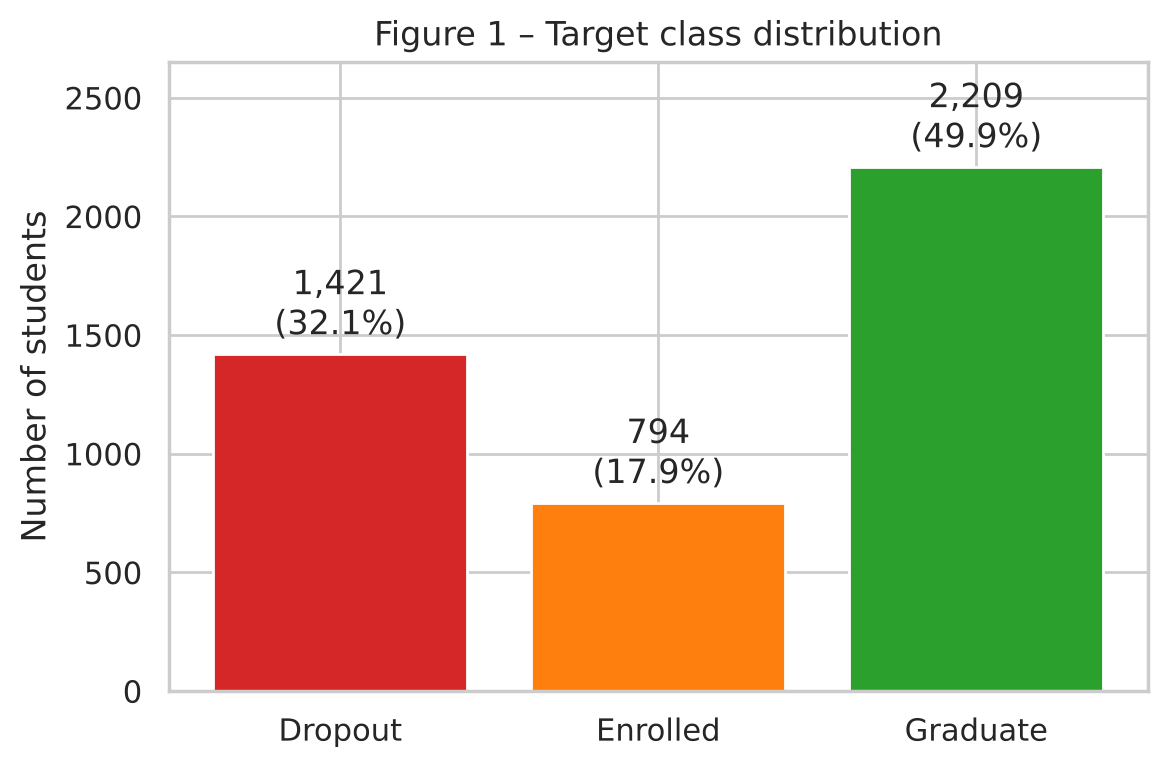

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(target_counts.index, target_counts.values,
              color=[PALETTE[c] for c in target_counts.index])
ax.bar_label(bars, labels=[f"{n:,}\n({p}%)" for n, p in zip(target_table["count"], target_table["share %"])],
             padding=3)
ax.set_title("Figure 1 – Target class distribution")
ax.set_ylabel("Number of students")
ax.set_ylim(0, target_counts.max() * 1.2)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_target_distribution.png", dpi=200)
plt.show()

**Interpretation – Figure 1**
- The target is **imbalanced**: Graduate 49.9%, Dropout 32.1%, Enrolled 17.9%.
- A model that always predicts *Graduate* would already score **~50% accuracy** while never identifying a single
  dropout. Accuracy alone is therefore misleading here; **macro-F1** and **per-class recall** (especially Dropout
  recall) are the more honest metrics.
- **Enrolled** is the minority class and is conceptually "in between" (still studying after the normal course
  length). It is likely to be the hardest class to predict.
- **Modelling consequence:** use a **stratified** train/test split and **StratifiedKFold** so every fold keeps these
  proportions, and consider **class weights or SMOTE inside the training folds only**.

## 4. Descriptive statistics and suspicious values

In [8]:
num = numeric_cols(df)
df[num].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Application order,4424.0,1.73,1.31,0.00,1.00,1.00,2.00,9.00
Previous qualification (grade),4424.0,132.61,13.19,95.00,125.00,133.10,140.00,190.00
Admission grade,4424.0,126.98,14.48,95.00,117.90,126.10,134.80,190.00
Age at enrollment,4424.0,23.27,7.59,17.00,19.00,20.00,25.00,70.00
Curricular units 1st sem (credited),4424.0,0.71,2.36,0.00,0.00,0.00,0.00,20.00
Curricular units 1st sem (enrolled),4424.0,6.27,2.48,0.00,5.00,6.00,7.00,26.00
Curricular units 1st sem (evaluations),4424.0,8.30,4.18,0.00,6.00,8.00,10.00,45.00
Curricular units 1st sem (approved),4424.0,4.71,3.09,0.00,3.00,5.00,6.00,26.00
Curricular units 1st sem (grade),4424.0,10.64,4.84,0.00,11.00,12.29,13.40,18.88
Curricular units 1st sem (without evaluations),4424.0,0.14,0.69,0.00,0.00,0.00,0.00,12.00


Most ranges are plausible: admission and previous-qualification grades are on a 0–200 scale (observed 95–190),
ages run from 17 to 70, and the economic indicators are small national figures. Three things deserve a closer look.

In [9]:
# (a) A semester grade of 0 – is that a real grade?
grade0 = df["Curricular units 1st sem (grade)"] == 0
approved0 = df["Curricular units 1st sem (approved)"] == 0
print("Students with 1st-sem grade = 0:          ", grade0.sum())
print("…of whom passed at least one unit:        ", (grade0 & ~approved0).sum())
print("Students with 0 approved units:           ", approved0.sum())
print("Dropout rate when 0 units approved:       ", round((df.loc[approved0, TARGET] == "Dropout").mean() * 100, 1), "%")

Students with 1st-sem grade = 0:           718
…of whom passed at least one unit:         0
Students with 0 approved units:            718
Dropout rate when 0 units approved:        79.4 %


**(a) Grade = 0 is a placeholder, not a grade.** All 718 students with a 1st-semester grade of 0 passed *zero*
units – the grade is simply the average of approved units, so 0 means "no grade available". On the 0–20 Portuguese
scale nobody is actually awarded 0. Left as-is, it creates a huge artificial spike at 0 (visible as the low mean of
10.6 vs a median of 12.3). It is still **highly informative** – 79.4% of these students drop out – so the value
should not be deleted. The planned treatment is to keep it and add a clear indicator, discussed in Section 7.

In [10]:
# (b) Students enrolled in 0 units in the 1st semester
enrolled0 = df["Curricular units 1st sem (enrolled)"] == 0
print("Students enrolled in 0 units (1st sem):", enrolled0.sum())
print(df.loc[enrolled0, TARGET].value_counts().reindex(CLASS_ORDER))
print()
print("Of these, students with credited units:", (df.loc[enrolled0, "Curricular units 1st sem (credited)"] > 0).sum())

Students enrolled in 0 units (1st sem): 180
Target
Dropout     77
Enrolled    28
Graduate    75
Name: count, dtype: int64

Of these, students with credited units: 0


**(b) 180 students enrolled in 0 units** in their first semester – yet 75 of them still graduated, and none of
them had units credited from previous study. The dataset documentation does not explain this (possibilities include
programme structures that start later, or recording gaps). Because there is no documented reason to treat the
rows as errors, **they are kept**, and this is noted as a **data-quality limitation**.

In [11]:
# (c) Age outliers and rare categories
print("Age at enrolment – median:", df["Age at enrollment"].median(),
      "| over 40:", (df["Age at enrollment"] > 40).sum())
print()
print("Marital status counts:", df["Marital status"].value_counts().to_dict())
print("Nationality: share of code 1 (Portuguese) =", round((df["Nationality"] == 1).mean() * 100, 1), "%")
print("Course sizes (smallest 3):", df["Course"].value_counts().tail(3).to_dict())

Age at enrolment – median: 20.0 | over 40: 225

Marital status counts: {1: 3919, 2: 379, 4: 91, 5: 25, 6: 6, 3: 4}
Nationality: share of code 1 (Portuguese) = 97.5 %
Course sizes (smallest 3): {9130: 141, 9556: 86, 33: 12}


**(c) Outliers and rare categories**
- **Age** is right-skewed (median 20, max 70; a minority of mature students over 40). These are real students, not
  errors, so they are **kept**. Tree models are unaffected by skew; for scale-sensitive models (Logistic Regression,
  SVM, KNN) the feature will be **standardised**.
- **Nationality** is 97.5% Portuguese and **Marital status** is 88.6% single. These features carry little
  information and some codes have fewer than 10 students, which matters for one-hot encoding (near-empty columns)
  and for the fairness discussion (very small groups cannot be evaluated reliably).
- One **Course** code has only 12 students.

## 5. Feature–target relationships

In [12]:
# Dropout rate (%) for each 0/1 flag
flag_rates = []
for col in ["Tuition fees up to date", "Debtor", "Scholarship holder", "Gender",
            "Displaced", "Daytime/evening attendance"]:
    rates = pd.crosstab(df[col], df[TARGET], normalize="index")["Dropout"] * 100
    flag_rates.append({"feature": col, "value = 0": rates.get(0), "value = 1": rates.get(1)})
flag_rates = pd.DataFrame(flag_rates).set_index("feature").round(1)
flag_rates

,value = 0,value = 1
feature,,
Tuition fees up to date,86.6,24.7
Debtor,28.3,62.0
Scholarship holder,38.7,12.2
Gender,25.1,45.1
Displaced,37.6,27.6
Daytime/evening attendance,42.9,30.8


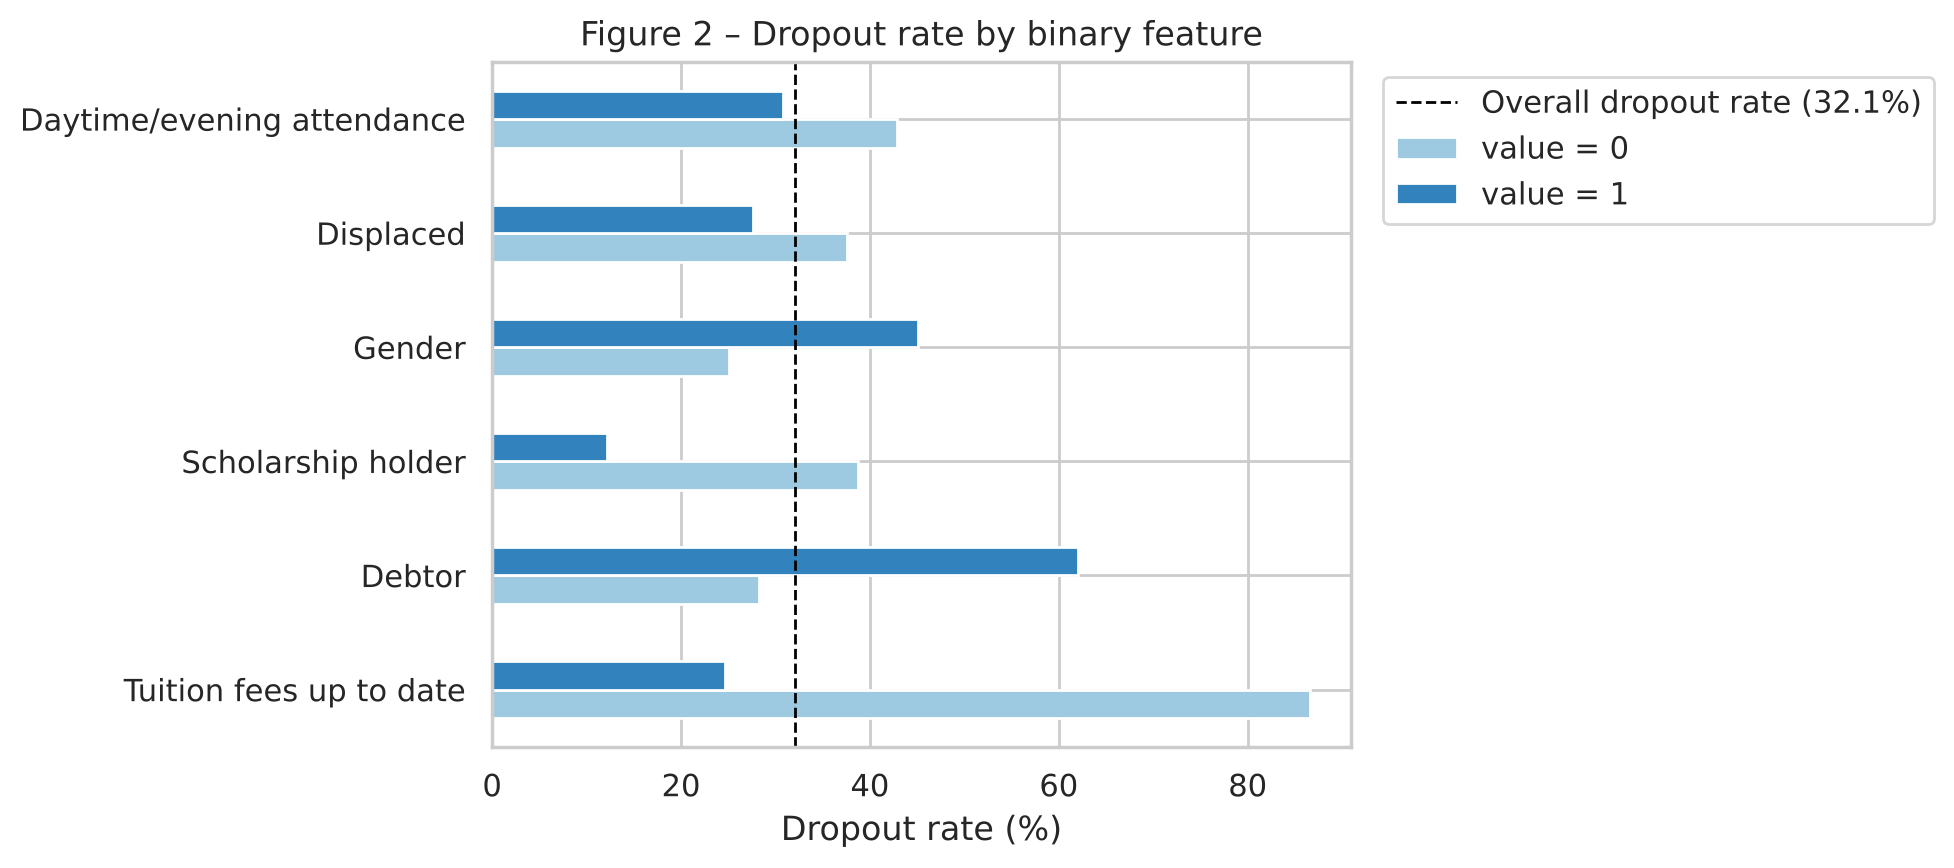

In [13]:
ax = flag_rates.plot(kind="barh", figsize=(10, 4.5), color=["#9ecae1", "#3182bd"])
ax.axvline((df[TARGET] == "Dropout").mean() * 100, color="black", linestyle="--", linewidth=1,
           label="Overall dropout rate (32.1%)")
ax.set_title("Figure 2 – Dropout rate by binary feature")
ax.set_xlabel("Dropout rate (%)")
ax.set_ylabel("")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig(FIG_DIR / "fig2_dropout_rate_by_flag.png", dpi=200)
plt.show()

**Interpretation – Figure 2** (Gender: 1 = male, 0 = female; Daytime/evening: 1 = daytime)
- **Financial status is the strongest pattern.** Students whose tuition fees are *not* up to date drop out at
  **86.6%** vs 24.7%; debtors at **62.0%** vs 28.3%. Scholarship holders drop out far less (12.2% vs 38.7%).
- **Gender:** male students drop out at 45.1% vs 25.1% for female students.
- Evening attendance (42.9% vs 30.8%) and not being displaced also associate with higher dropout.
- These are **associations, not causes** – e.g. unpaid fees may be a *symptom* of a student already disengaging.
- **Leakage check – "would we know this at prediction time?"** *Tuition fees up to date* and *Debtor* describe
  the student's status recorded by the institution; if they were measured **at the end** of the course they could
  partly reflect the outcome. The dataset documentation does not state the exact timestamp, so this is recorded as
  a **limitation** to discuss in the report.
- **Responsible-AI flag:** gender is a protected characteristic. Using it may raise predictive power but risks
  treating students differently by sex. This will be examined in the report (e.g. comparing errors by gender).

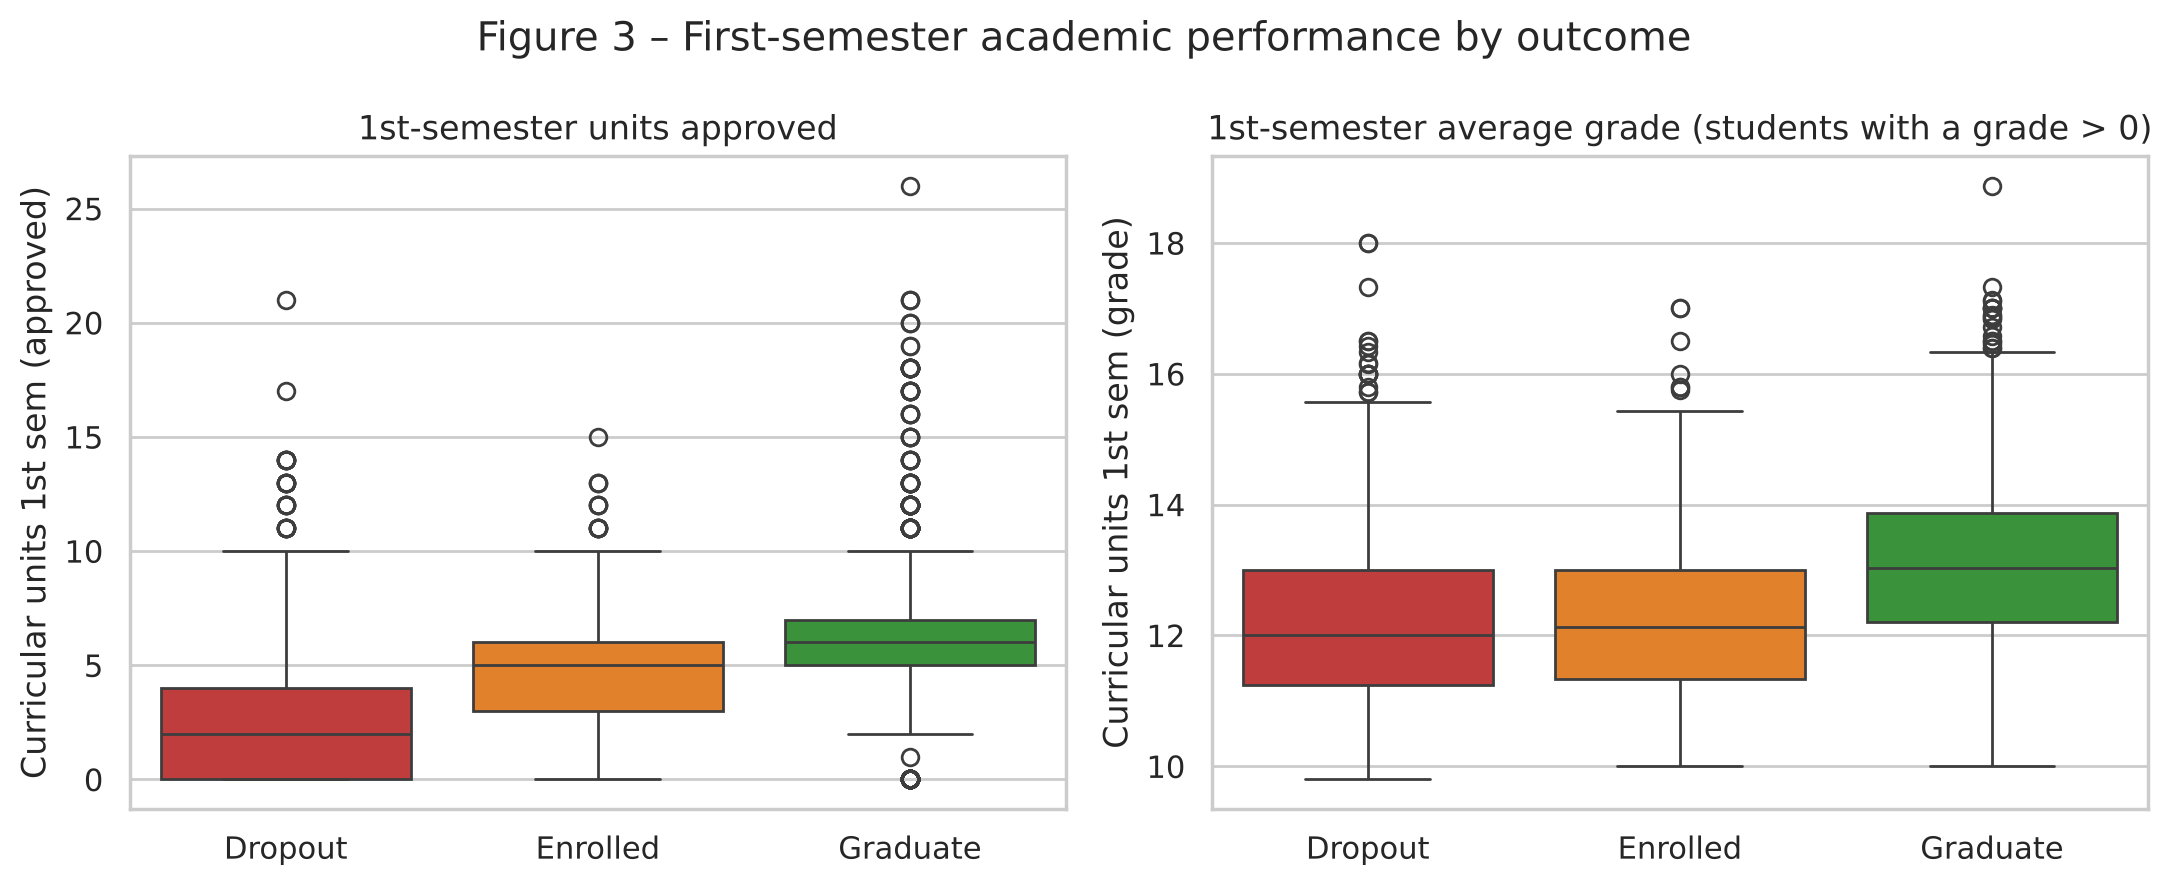

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.boxplot(data=df, x=TARGET, y="Curricular units 1st sem (approved)", order=CLASS_ORDER,
            hue=TARGET, palette=PALETTE, legend=False, ax=axes[0])
axes[0].set_title("1st-semester units approved")
axes[0].set_xlabel("")
sns.boxplot(data=df[df["Curricular units 1st sem (grade)"] > 0], x=TARGET,
            y="Curricular units 1st sem (grade)", order=CLASS_ORDER,
            hue=TARGET, palette=PALETTE, legend=False, ax=axes[1])
axes[1].set_title("1st-semester average grade (students with a grade > 0)")
axes[1].set_xlabel("")
fig.suptitle("Figure 3 – First-semester academic performance by outcome")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_first_semester_by_target.png", dpi=200)
plt.show()

In [15]:
df.groupby(TARGET)[["Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
                    "Admission grade", "Age at enrollment"]].median().reindex(CLASS_ORDER)

,Curricular units 1st sem (approved),Curricular units 1st sem (grade),Admission grade,Age at enrollment
Target,,,,
Dropout,2.0,10.928571,123.6,23.0
Enrolled,5.0,12.000000,124.1,20.0
Graduate,6.0,13.000000,127.4,19.0


**Interpretation – Figure 3**
- First-semester performance separates the classes clearly. The median **dropout** passed **2** units, the median
  **enrolled** student 5 and the median **graduate** 6. **40%** of dropouts passed no units at all, compared with
  3.5% of graduates.
- Among students who *do* have a grade, graduates' grades are higher, but the boxes overlap. **Units approved is a
  stronger signal than grade.**
- **Enrolled** students sit between the two groups on both measures, which confirms that this class will be the
  hardest to separate.
- This supports the research question: **useful signal exists by the end of semester 1**, which is early enough for
  an intervention.

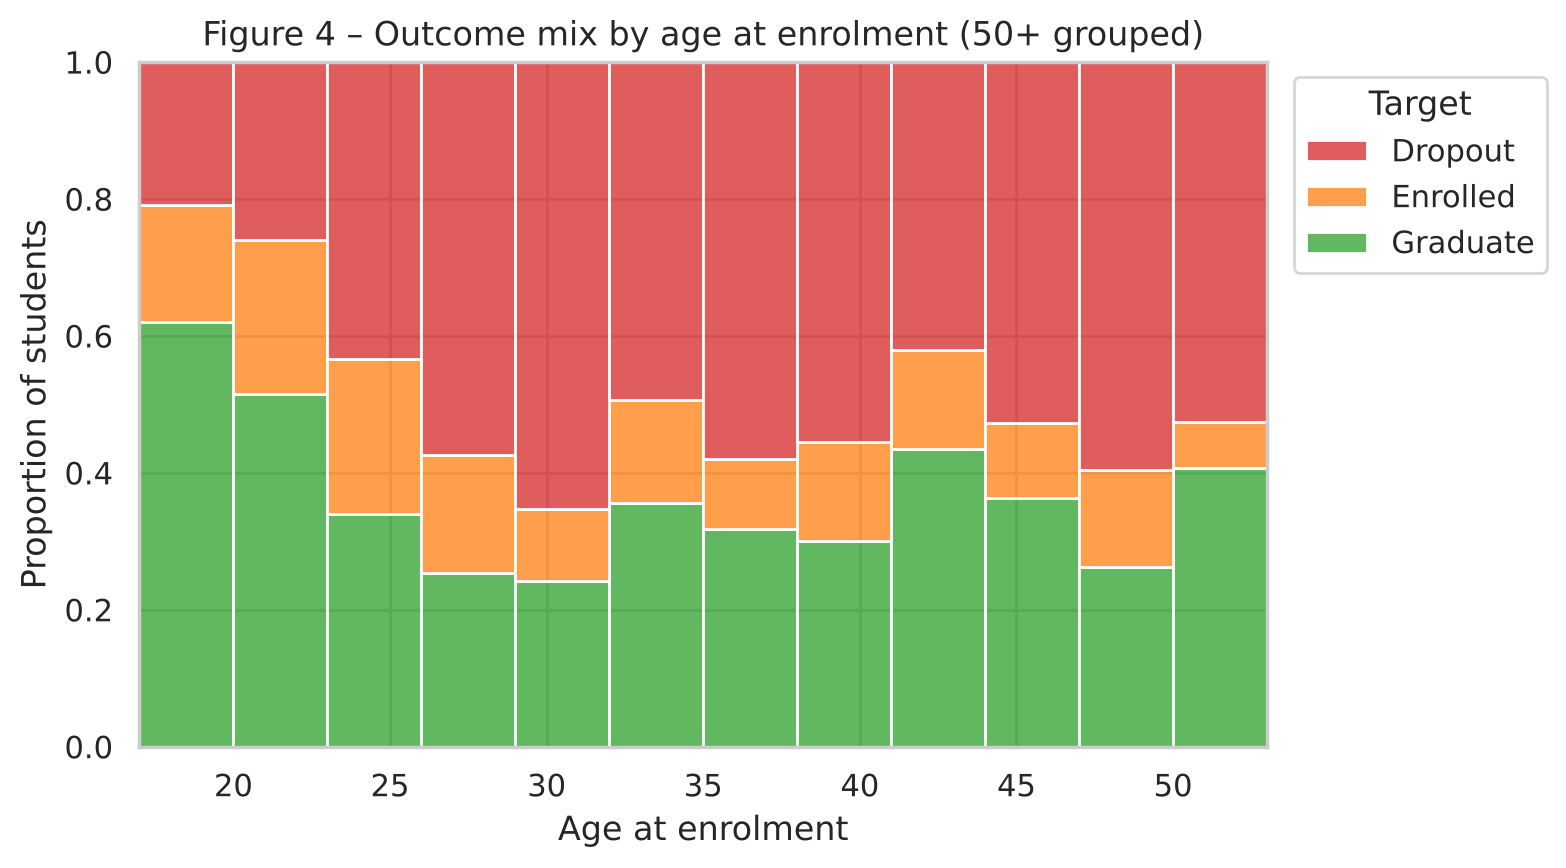

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
# Ages above 50 are grouped into one bin: individual bins there hold only a handful of students
age_plot = df.assign(age_capped=df["Age at enrollment"].clip(upper=50))
sns.histplot(data=age_plot, x="age_capped", hue=TARGET, hue_order=CLASS_ORDER, palette=PALETTE,
             multiple="fill", bins=range(17, 54, 3), ax=ax)
ax.set_title("Figure 4 – Outcome mix by age at enrolment (50+ grouped)")
ax.set_xlabel("Age at enrolment")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.01, 1))
ax.set_ylabel("Proportion of students")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_outcome_by_age.png", dpi=200)
plt.show()

**Interpretation – Figure 4**
- Students who enrol **straight from school (17–20)** are mostly graduates. From about age 26 onward the dropout
  share rises sharply and is the majority in most older bins.
- The median dropout enrolled at 23 vs 19 for graduates. Older students more often balance study with work or
  family, though the data cannot confirm the reason.
- The relationship is **non-linear** (flat then rising), which tree-based models capture naturally; linear models
  may need it scaled and will only fit a straight-line trend.
- Only 225 students enrolled over 40, so the right-hand bins are based on small groups and are noisier; ages
  above 50 are grouped into one bin for that reason.

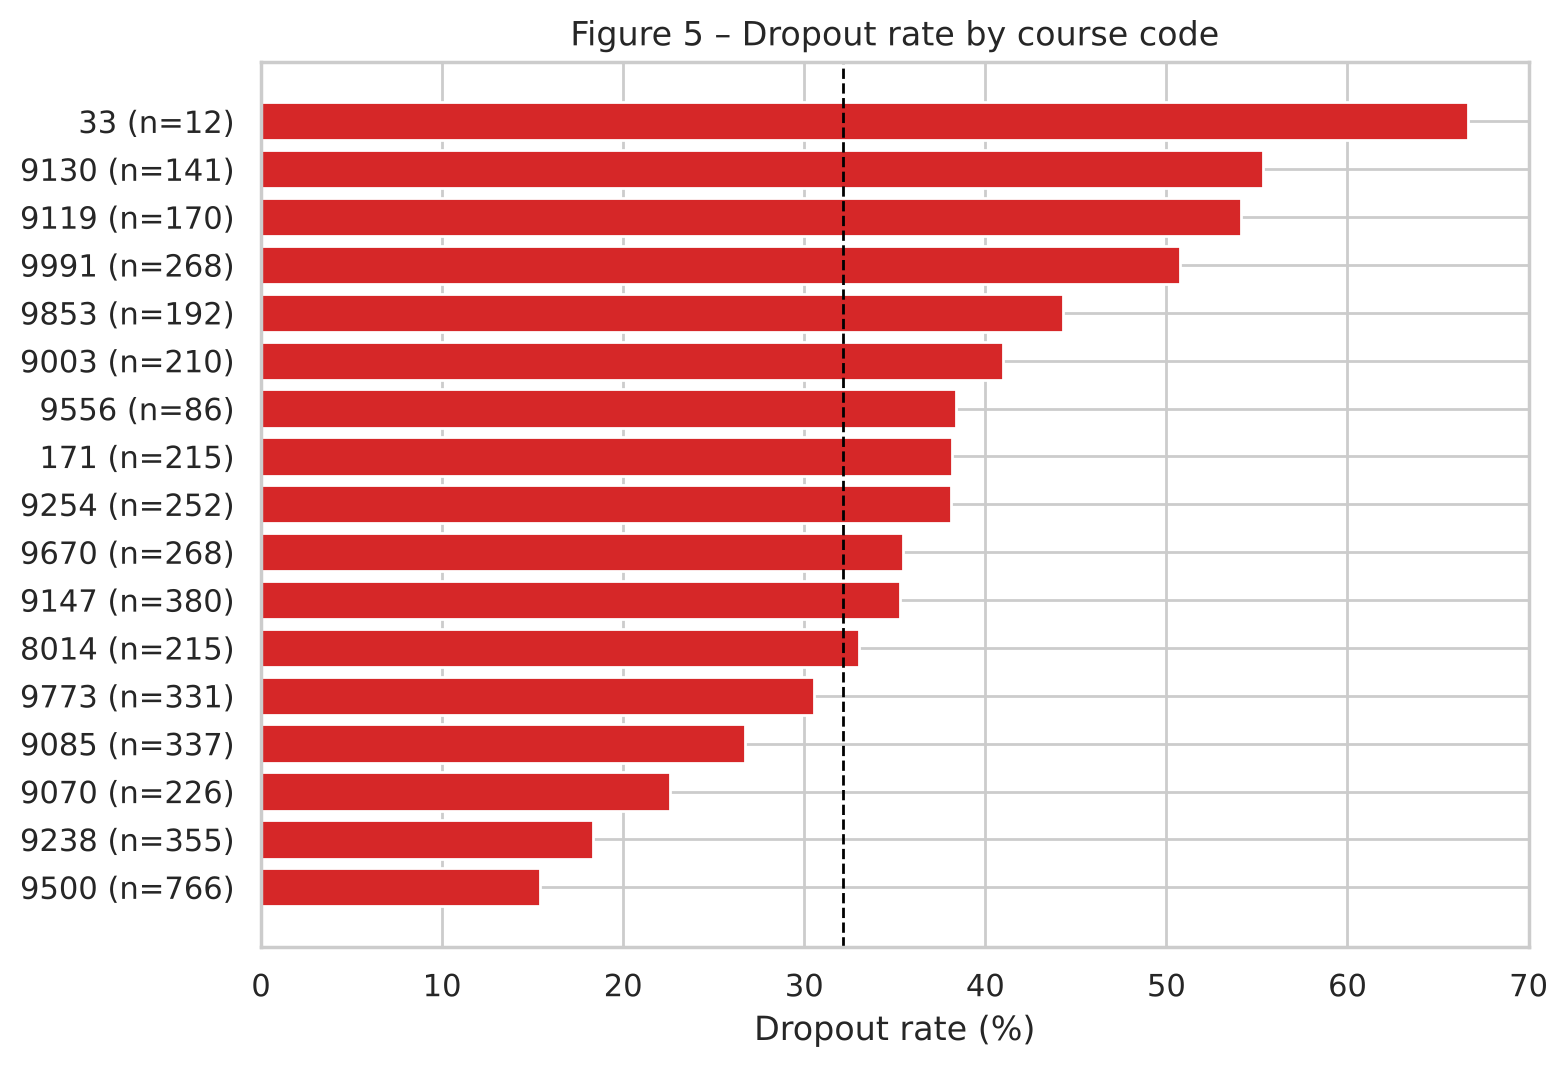

In [17]:
course_rate = (pd.crosstab(df["Course"], df[TARGET], normalize="index")["Dropout"] * 100).sort_values()
course_n = df["Course"].value_counts()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh([f"{c} (n={course_n[c]})" for c in course_rate.index], course_rate.values, color="#d62728")
ax.axvline((df[TARGET] == "Dropout").mean() * 100, color="black", linestyle="--", linewidth=1)
ax.set_title("Figure 5 – Dropout rate by course code")
ax.set_xlabel("Dropout rate (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_dropout_by_course.png", dpi=200)
plt.show()

**Interpretation – Figure 5**
- Dropout varies from roughly **15% to 67% depending on the course**, so the programme a student joins is
  informative.
- Because course codes are unordered, the variable must be **one-hot encoded** – a model must not read code 9500
  as "larger" than 33.
- The smallest course (n = 12) gives an unreliable rate; one-hot columns for tiny groups add little and may
  encourage overfitting.

## 6. Correlations and the 2nd-semester decision

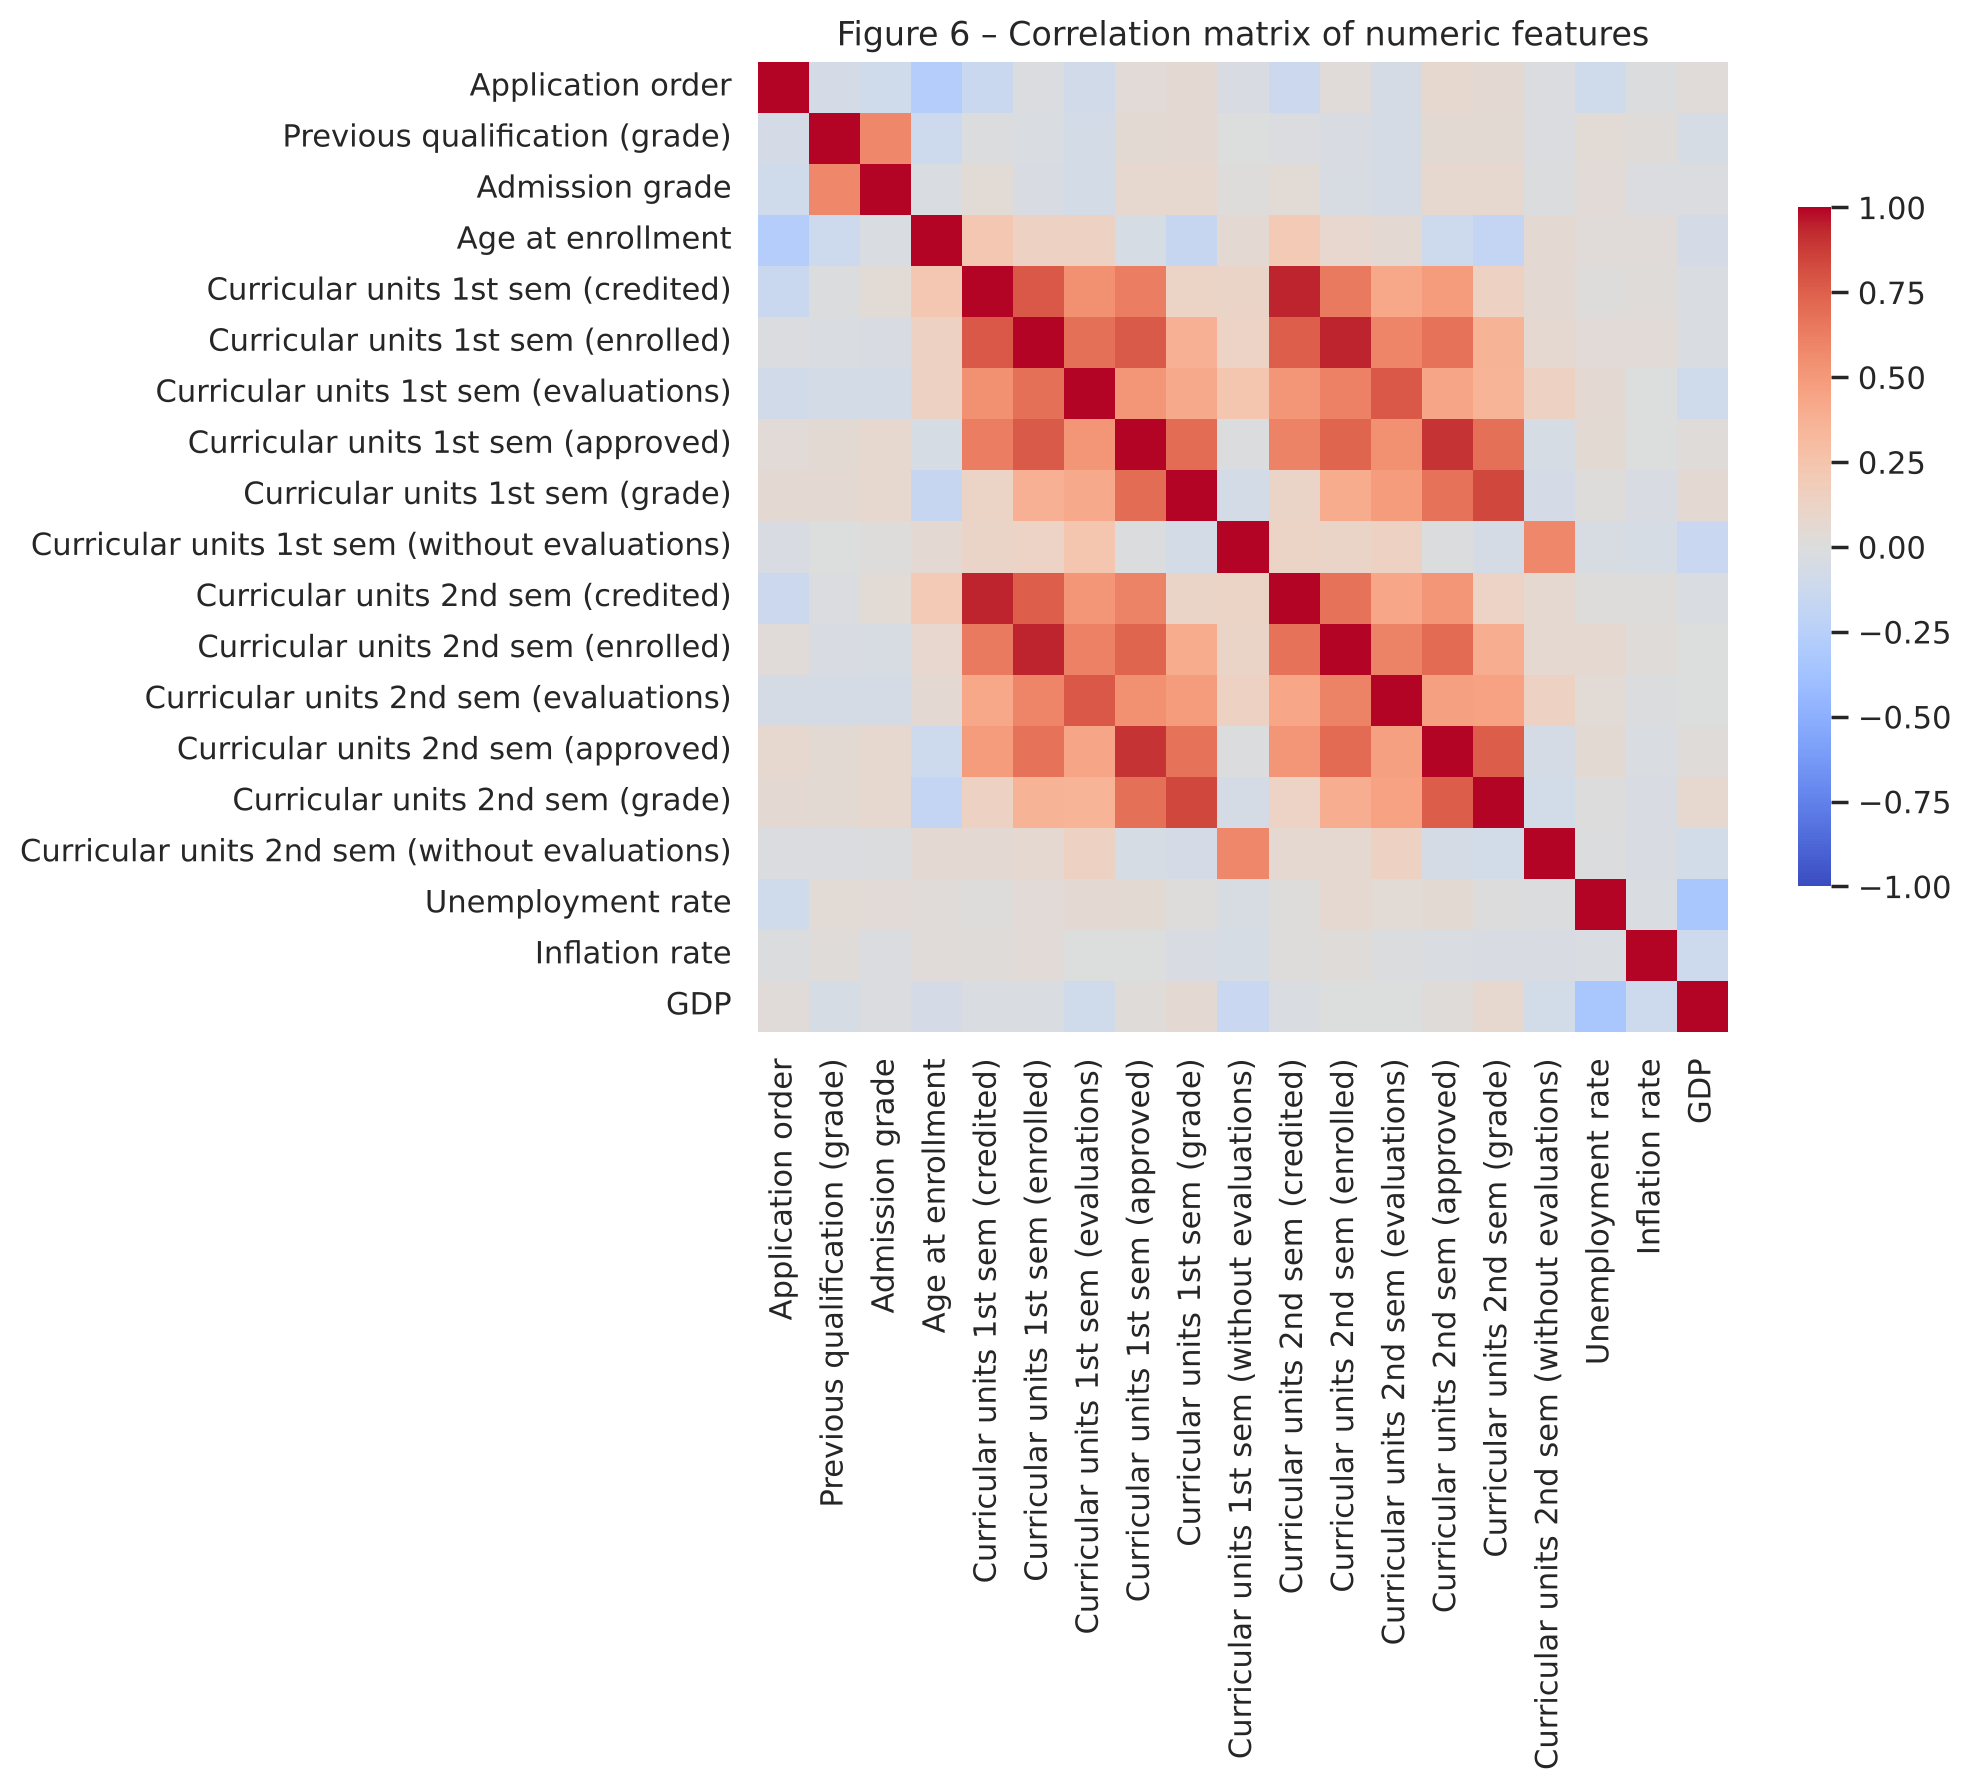

In [18]:
corr = df[num].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Figure 6 – Correlation matrix of numeric features")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6_correlation_heatmap.png", dpi=200)
plt.show()

In [19]:
# Strongest pairs (excluding self-correlation)
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(10).round(3)

Curricular units 1st sem (credited)     Curricular units 2nd sem (credited)       0.945
Curricular units 1st sem (enrolled)     Curricular units 2nd sem (enrolled)       0.943
Curricular units 1st sem (approved)     Curricular units 2nd sem (approved)       0.904
Curricular units 1st sem (grade)        Curricular units 2nd sem (grade)          0.837
Curricular units 1st sem (evaluations)  Curricular units 2nd sem (evaluations)    0.779
Curricular units 1st sem (credited)     Curricular units 1st sem (enrolled)       0.774
Curricular units 1st sem (enrolled)     Curricular units 1st sem (approved)       0.769
Curricular units 2nd sem (approved)     Curricular units 2nd sem (grade)          0.761
Curricular units 1st sem (enrolled)     Curricular units 2nd sem (credited)       0.754
Curricular units 1st sem (approved)     Curricular units 2nd sem (enrolled)       0.734
dtype: float64

**Interpretation – Figure 6**
- The curricular-unit variables form a **tightly correlated block**. Each 1st-semester variable is very strongly
  correlated with its own 2nd-semester counterpart (e.g. units approved: r ≈ 0.90).
- Admission grade and previous qualification grade are moderately correlated, as expected.
- The economic indicators (unemployment, inflation, GDP) take only **10 distinct combinations** across 4,424
  students – they are national values for the year a student enrolled, so they act as an *enrolment-year* marker
  rather than individual information.
- High correlation (**multicollinearity**) makes Logistic Regression coefficients unstable and hard to interpret,
  though it does not harm predictions much. Tree ensembles are largely unaffected.

In [20]:
sem1, sem2 = semester_cols(df, "1st"), semester_cols(df, "2nd")
pd.DataFrame({"1st semester": sem1, "2nd semester": sem2,
              "correlation": [round(df[a].corr(df[b]), 3) for a, b in zip(sem1, sem2)]})

,1st semester,2nd semester,correlation
0,Curricular units 1st sem (credited),Curricular units 2nd sem (credited),0.945
1,Curricular units 1st sem (enrolled),Curricular units 2nd sem (enrolled),0.943
2,Curricular units 1st sem (evaluations),Curricular units 2nd sem (evaluations),0.779
3,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),0.904
4,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),0.837
5,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (without evaluations),0.583


**Decision – exclude the 2nd-semester features.**

The six `Curricular units 2nd sem (…)` columns are **removed from X** before any split or modelling. The full
justification is given in the report (Section 3 – Feature decisions). In short, the research question is about
**early** prediction using information available by the end of the first semester, and the table above shows that
2nd-semester variables largely duplicate the 1st-semester ones.

As a supplementary comparison, the effect of including them may be reported separately, but the **main model uses
1st-semester information only**.

## 7. EDA findings → preprocessing decisions

| # | EDA finding | Decision for modelling | Why |
|---|---|---|---|
| 1 | No missing values, no duplicates | No imputation, no row removal | Nothing to fix; avoids unnecessary changes |
| 2 | 9 categorical columns stored as integer codes | **One-hot encode** (`handle_unknown="ignore"`) | Codes are unordered; treating them as numbers implies false order |
| 3 | 8 binary 0/1 flags | Use as-is | Already correctly encoded |
| 4 | Imbalanced target (50 / 32 / 18 %) | Stratified split + **StratifiedKFold**; macro-F1 as main metric; test class weights / SMOTE **inside training folds only** | Accuracy rewards majority-class guessing |
| 5 | Grade = 0 means "no units approved" | Keep the value (highly predictive); note as a sentinel | Deleting it would throw away the strongest dropout signal |
| 6 | 180 students enrolled in 0 units | Keep | Plausible, undocumented as an error; noted as limitation |
| 7 | Skewed age, very different feature scales | **StandardScaler** for LR / SVM / KNN; none for trees | Distance/weight-based models need comparable scales |
| 8 | 2nd-semester units strongly duplicate 1st-semester units | **Drop 2nd-semester columns** | Early-prediction framing (justified in report) |
| 9 | Fees/debtor timing undocumented | Keep, flag as possible leakage in limitations | Cannot verify when the value was recorded |
| 10 | Gender strongly associated with dropout | Keep for modelling; analyse errors by gender in Responsible AI section | Fairness must be checked, not assumed |

**Leakage safeguard:** every learned step (scaler, encoder, SMOTE) will be placed inside a scikit-learn
`Pipeline`, so it is fitted on training folds only and the locked test set is never seen until the single final
evaluation.